In [1]:
# Core
import pandas as pd
import numpy as np

# NLP
import spacy
from collections import Counter

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Load spaCy model
nlp = spacy.load("en_core_web_sm")

In [2]:
df = pd.read_csv("NLP_Supplier_Risk_Incidents.csv")

df.head()

,Company,Supplier_ID,Month,Incident_Category,Incident_Description
0,Toyota Kirloskar Motor,S2824,2024-01,Labor Disruption,labor shortage impacted supplier output
1,Maruti Suzuki,S3286,2024-12,Logistics Delay,delay due to port congestion
2,Toyota Kirloskar Motor,S7912,2024-01,Logistics Delay,delay due to port congestion
3,Maruti Suzuki,S4811,2024-09,Capacity Constraint,supplier operating at full capacity
4,Toyota Kirloskar Motor,S4257,2024-12,Capacity Constraint,overutilization caused delayed deliveries


In [3]:
def preprocess_text(text):
    doc = nlp(text.lower())
    tokens = [
        token.lemma_
        for token in doc
        if token.is_alpha and not token.is_stop
    ]
    return tokens

In [4]:
df["tokens"] = df["Incident_Description"].apply(preprocess_text)
df.head()

,Company,Supplier_ID,Month,Incident_Category,Incident_Description,tokens
0,Toyota Kirloskar Motor,S2824,2024-01,Labor Disruption,labor shortage impacted supplier output,"[labor, shortage, impact, supplier, output]"
1,Maruti Suzuki,S3286,2024-12,Logistics Delay,delay due to port congestion,"[delay, port, congestion]"
2,Toyota Kirloskar Motor,S7912,2024-01,Logistics Delay,delay due to port congestion,"[delay, port, congestion]"
3,Maruti Suzuki,S4811,2024-09,Capacity Constraint,supplier operating at full capacity,"[supplier, operate, capacity]"
4,Toyota Kirloskar Motor,S4257,2024-12,Capacity Constraint,overutilization caused delayed deliveries,"[overutilization, cause, delay, delivery]"


In [5]:
all_tokens = [token for tokens in df["tokens"] for token in tokens]

token_freq = Counter(all_tokens)
token_freq.most_common(15)

[('supplier', 353),
 ('delay', 336),
 ('issue', 241),
 ('quality', 153),
 ('capacity', 148),
 ('supply', 145),
 ('cause', 142),
 ('impact', 119),
 ('disrupt', 115),
 ('labor', 102),
 ('strike', 102),
 ('production', 94),
 ('component', 93),
 ('material', 64),
 ('detect', 64)]

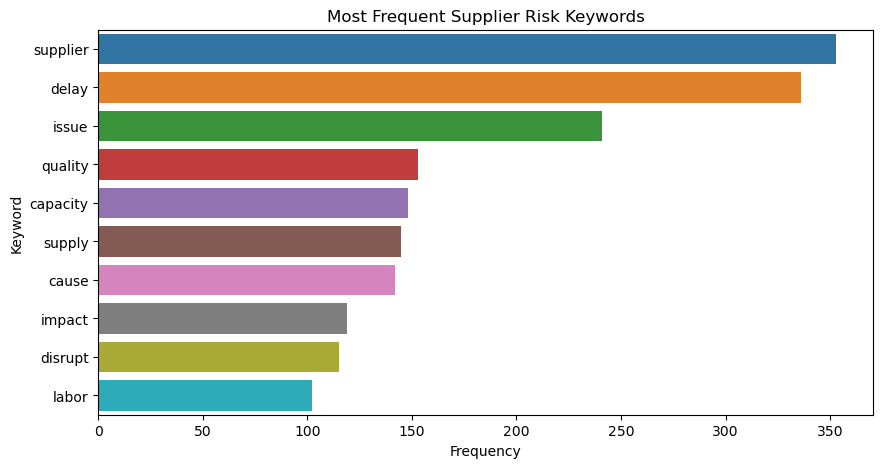

In [6]:
top_keywords = token_freq.most_common(10)

words, counts = zip(*top_keywords)

plt.figure(figsize=(10,5))
sns.barplot(x=list(counts), y=list(words))
plt.title("Most Frequent Supplier Risk Keywords")
plt.xlabel("Frequency")
plt.ylabel("Keyword")
plt.show()

In [7]:
company_keywords = {}

for company in df["Company"].unique():
    tokens = df[df["Company"] == company]["tokens"]
    flat = [t for tokens in tokens for t in tokens]
    company_keywords[company] = Counter(flat).most_common(10)

company_keywords


{'Toyota Kirloskar Motor': [('supplier', 127),
  ('delay', 98),
  ('issue', 82),
  ('capacity', 58),
  ('quality', 55),
  ('cause', 44),
  ('supply', 40),
  ('disrupt', 40),
  ('impact', 39),
  ('production', 37)],
 'Maruti Suzuki': [('delay', 116),
  ('supplier', 116),
  ('issue', 76),
  ('cause', 55),
  ('capacity', 54),
  ('supply', 51),
  ('quality', 48),
  ('impact', 39),
  ('labor', 38),
  ('strike', 36)],
 'Hyundai Motor India': [('delay', 122),
  ('supplier', 110),
  ('issue', 83),
  ('supply', 54),
  ('quality', 50),
  ('cause', 43),
  ('disrupt', 42),
  ('impact', 41),
  ('strike', 39),
  ('component', 37)]}

In [8]:
monthly_risk = (
    df.groupby(["Month", "Incident_Category"])
    .size()
    .reset_index(name="Incident_Count")
)

monthly_risk.head()

,Month,Incident_Category,Incident_Count
0,2024-01,Capacity Constraint,14
1,2024-01,Labor Disruption,17
2,2024-01,Logistics Delay,18
3,2024-01,Quality Issue,17
4,2024-01,Weather Event,14


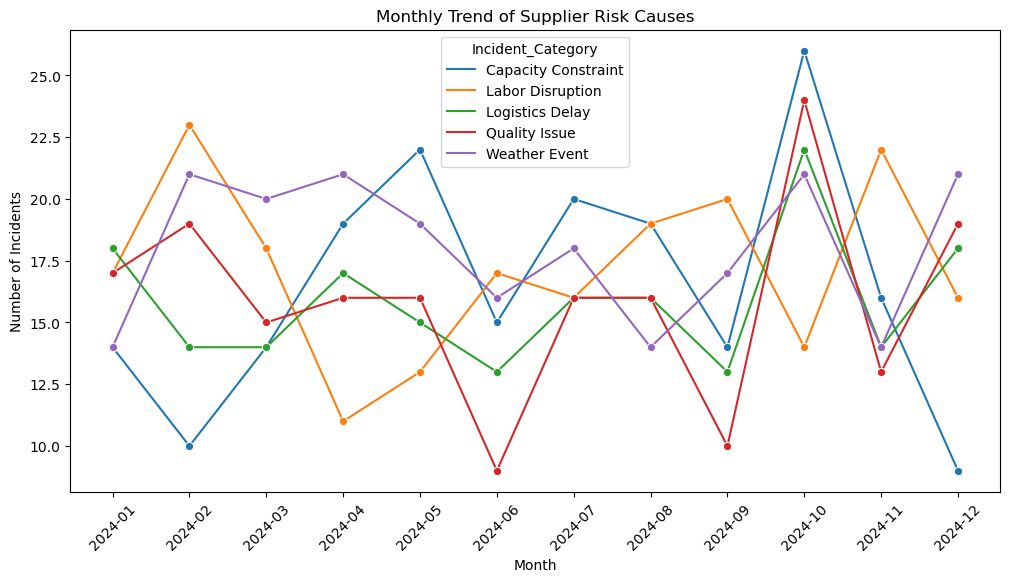

In [9]:
plt.figure(figsize=(12,6))
sns.lineplot(
    data=monthly_risk,
    x="Month",
    y="Incident_Count",
    hue="Incident_Category",
    marker="o"
)
plt.xticks(rotation=45)
plt.title("Monthly Trend of Supplier Risk Causes")
plt.xlabel("Month")
plt.ylabel("Number of Incidents")
plt.show()


In [10]:
risk_weights = {
    "logistics": 3,
    "delay": 3,
    "quality": 4,
    "defect": 4,
    "strike": 5,
    "labor": 5,
    "weather": 4,
    "flood": 4,
    "capacity": 3
}


In [11]:
def calculate_risk_score(tokens):
    score = 0
    for token in tokens:
        score += risk_weights.get(token, 0)
    return score


In [12]:
df["NLP_Risk_Score"] = df["tokens"].apply(calculate_risk_score)

df[["Incident_Description", "NLP_Risk_Score"]].head()


,Incident_Description,NLP_Risk_Score
0,labor shortage impacted supplier output,5
1,delay due to port congestion,3
2,delay due to port congestion,3
3,supplier operating at full capacity,3
4,overutilization caused delayed deliveries,3


In [13]:
supplier_risk = (
    df.groupby(["Company", "Supplier_ID"])
    .agg(
        Avg_NLP_Risk_Score=("NLP_Risk_Score", "mean"),
        Incident_Count=("NLP_Risk_Score", "count")
    )
    .reset_index()
)

supplier_risk.head()


,Company,Supplier_ID,Avg_NLP_Risk_Score,Incident_Count
0,Hyundai Motor India,S1071,3.0,1
1,Hyundai Motor India,S1072,4.0,1
2,Hyundai Motor India,S1100,4.0,1
3,Hyundai Motor India,S1157,4.0,1
4,Hyundai Motor India,S1186,4.0,1


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20,
    stop_words="english"
)

tfidf_matrix = tfidf.fit_transform(df["Incident_Description"])

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf.get_feature_names_out()
)

tfidf_df.head()


,capacity,caused,cyclone,delay,delayed,detected,disrupted,impact,issue,issues,labor,material,operations,plant,production,quality,strike,supplier,supply,transportation
0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.848791,0.0,0.0,0.0,0.0,0.0,0.0,0.528729,0.0,0.0
1,0.000000,0.000000,0.0,1.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
2,0.000000,0.000000,0.0,1.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
3,0.818425,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.574614,0.0,0.0
4,0.000000,0.708776,0.0,0.0,0.705434,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0


# Time Series

In [15]:
monthly_ts = (
    df.groupby("Month")
    .size()
    .reset_index(name="Incident_Count")
)

monthly_ts["Month"] = pd.to_datetime(monthly_ts["Month"])
monthly_ts = monthly_ts.sort_values("Month")
monthly_ts.set_index("Month", inplace=True)

monthly_ts.head()


,Incident_Count
Month,
2024-01-01,80
2024-02-01,87
2024-03-01,81
2024-04-01,84
2024-05-01,85


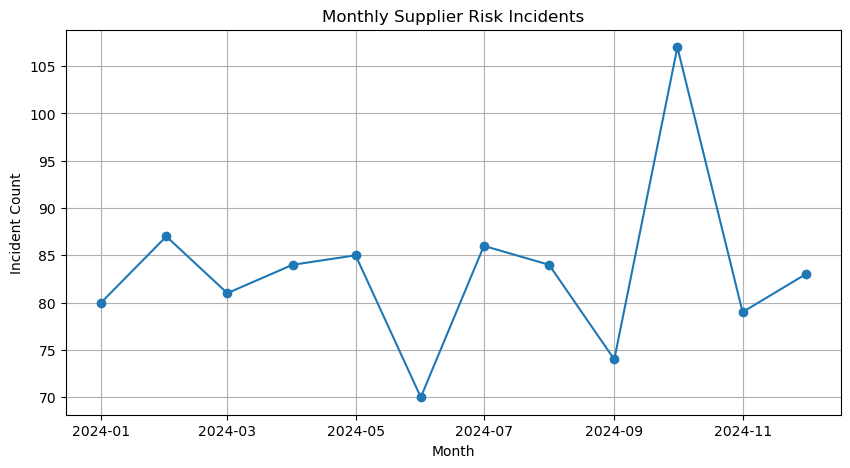

In [16]:
plt.figure(figsize=(10,5))
plt.plot(monthly_ts, marker="o")
plt.title("Monthly Supplier Risk Incidents")
plt.xlabel("Month")
plt.ylabel("Incident Count")
plt.grid(True)
plt.show()


# ADF Test

In [18]:
pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 7.2 MB/s  0:00:01 7.1 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [statsmodels] 1/2 [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [19]:
from statsmodels.tsa.stattools import adfuller

adf_test = adfuller(monthly_ts["Incident_Count"])

print("ADF Statistic:", adf_test[0])
print("p-value:", adf_test[1])


ADF Statistic: 1.9831162979810737
p-value: 0.9986506069005308


In [21]:
monthly_ts_diff = monthly_ts.diff().dropna()

adf_test_diff = adfuller(monthly_ts_diff["Incident_Count"])
print("Differenced p-value:", adf_test_diff[1])


Differenced p-value: 0.018789574490435213


In [22]:
from statsmodels.tsa.arima.model import ARIMA

In [23]:
model = ARIMA(
    monthly_ts["Incident_Count"],
    order=(1,1,1)   # ARIMA(p,d,q)
)

model_fit = model.fit()

print(model_fit.summary())


                               SARIMAX Results                                
Dep. Variable:         Incident_Count   No. Observations:                   12
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 -40.090
Date:                Tue, 10 Feb 2026   AIC                             86.179
Time:                        23:00:17   BIC                             87.373
Sample:                    01-01-2024   HQIC                            85.427
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3823      0.733     -0.521      0.602      -1.819       1.055
ma.L1         -0.9997    519.916     -0.002      0.998   -1020.017    1018.017
sigma2        63.8554   3.32e+04      0.002      0.9

/opt/anaconda3/envs/NLP/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/NLP/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/NLP/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [24]:
forecast = model_fit.forecast(steps=3)

forecast_df = pd.DataFrame({
    "Month": pd.date_range(
        start=monthly_ts.index[-1] + pd.DateOffset(months=1),
        periods=3,
        freq="MS"
    ),
    "Forecasted_Incident_Count": forecast
})

forecast_df


,Month,Forecasted_Incident_Count
2025-01-01,2025-01-01,83.582749
2025-02-01,2025-02-01,83.359971
2025-03-01,2025-03-01,83.445136


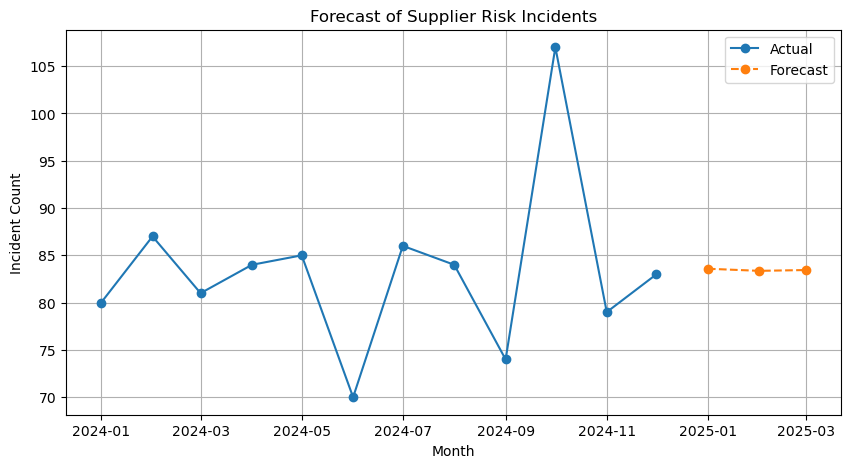

In [25]:
plt.figure(figsize=(10,5))
plt.plot(monthly_ts, label="Actual", marker="o")
plt.plot(forecast_df["Month"], forecast_df["Forecasted_Incident_Count"],
         label="Forecast", marker="o", linestyle="--")

plt.title("Forecast of Supplier Risk Incidents")
plt.xlabel("Month")
plt.ylabel("Incident Count")
plt.legend()
plt.grid(True)
plt.show()


# Monte Carlo Simulation

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = df = pd.read_csv("NLP_Supplier_Risk_Incidents.csv")

# Quick check
print(df.head())

                  Company Supplier_ID    Month    Incident_Category  \
0  Toyota Kirloskar Motor       S2824  2024-01     Labor Disruption   
1           Maruti Suzuki       S3286  2024-12      Logistics Delay   
2  Toyota Kirloskar Motor       S7912  2024-01      Logistics Delay   
3           Maruti Suzuki       S4811  2024-09  Capacity Constraint   
4  Toyota Kirloskar Motor       S4257  2024-12  Capacity Constraint   

                        Incident_Description  
0    labor shortage impacted supplier output  
1               delay due to port congestion  
2               delay due to port congestion  
3        supplier operating at full capacity  
4  overutilization caused delayed deliveries  


In [4]:
monthly_incidents = df.groupby(['Company', 'Month']).size().reset_index(name='Incident_Count')

In [5]:
supplier_volatility = df.groupby(['Company', 'Supplier_ID']).size().groupby(level=0).std().reset_index(name='Supplier_Risk_Volatility')


In [6]:
severity_mapping = {
    'Delay': 2,
    'Quality Issue': 3,
    'Compliance Issue': 4,
    'Logistics Disruption': 3,
    'Minor Delay': 1
}

df['Severity_Score'] = df['Incident_Category'].map(severity_mapping)


In [7]:
df['Description_Length'] = df['Incident_Description'].apply(lambda x: len(str(x)))

monthly_text_risk = df.groupby(['Company', 'Month'])['Description_Length'].mean().reset_index(name='Avg_Text_Risk')


In [9]:
monthly_severity = df.groupby(['Company', 'Month'])['Severity_Score'].mean().reset_index()

In [10]:
import numpy as np

n_simulations = 10000

# Compute historical statistics (example for one company)
incident_mean = monthly_incidents['Incident_Count'].mean()
incident_std = monthly_incidents['Incident_Count'].std()

severity_mean = monthly_severity['Severity_Score'].mean()
severity_std = monthly_severity['Severity_Score'].std()

text_mean = monthly_text_risk['Avg_Text_Risk'].mean()
text_std = monthly_text_risk['Avg_Text_Risk'].std()

vol_mean = supplier_volatility['Supplier_Risk_Volatility'].mean()
vol_std = supplier_volatility['Supplier_Risk_Volatility'].std()

simulated_index = []

for _ in range(n_simulations):
    
    sim_incidents = np.random.normal(incident_mean, incident_std)
    sim_severity = np.random.normal(severity_mean, severity_std)
    sim_text = np.random.normal(text_mean, text_std)
    sim_vol = np.random.normal(vol_mean, vol_std)
    
    disruption_index = (
        0.35 * sim_incidents +
        0.30 * sim_severity +
        0.20 * sim_vol +
        0.15 * sim_text
    )
    
    simulated_index.append(disruption_index)

simulated_index = np.array(simulated_index)


In [11]:
expected_risk = np.mean(simulated_index)
var_95 = np.percentile(simulated_index, 95)
prob_high_risk = np.mean(simulated_index > np.percentile(simulated_index, 75))

print("Expected Risk Index:", expected_risk)
print("95% Tail Risk:", var_95)
print("Probability of High Risk Month:", prob_high_risk)

Expected Risk Index: 16.825176504966763
95% Tail Risk: 19.697053567151638
Probability of High Risk Month: 0.25


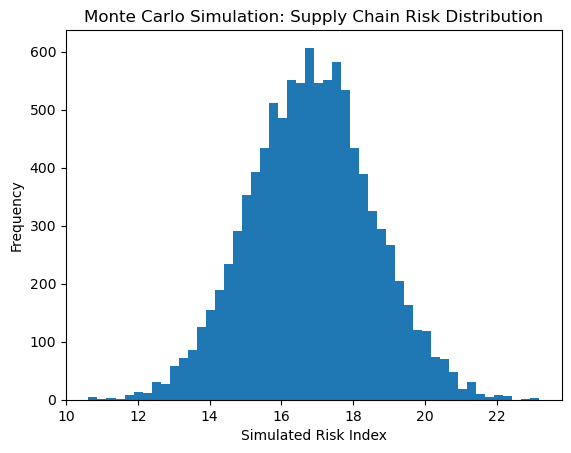

In [12]:
import matplotlib.pyplot as plt

plt.hist(simulated_index, bins=50)
plt.title("Monte Carlo Simulation: Supply Chain Risk Distribution")
plt.xlabel("Simulated Risk Index")
plt.ylabel("Frequency")
plt.show()


# Company wise monte carlo simulation

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = df = pd.read_csv("NLP_Supplier_Risk_Incidents.csv")

# Create severity mapping (adjust based on your categories)
severity_mapping = {
    'Delay': 2,
    'Quality Issue': 3,
    'Compliance Issue': 4,
    'Logistics Disruption': 3,
    'Minor Delay': 1
}

df['Severity_Score'] = df['Incident_Category'].map(severity_mapping)

# Description length proxy
df['Description_Length'] = df['Incident_Description'].apply(lambda x: len(str(x)))

# Monthly aggregation per company
monthly_data = df.groupby(['Company', 'Month']).agg(
    Incident_Count=('Supplier_ID', 'count'),
    Avg_Severity=('Severity_Score', 'mean'),
    Avg_Text_Risk=('Description_Length', 'mean')
).reset_index()


In [22]:
def monte_carlo_stress(data, shock_dict=None, n_simulations=10000):
    
    incident_mean = data['Incident_Count'].mean()
    incident_std = data['Incident_Count'].std()
    
    severity_mean = data['Avg_Severity'].mean()
    severity_std = data['Avg_Severity'].std()
    
    text_mean = data['Avg_Text_Risk'].mean()
    text_std = data['Avg_Text_Risk'].std()
    
    # Apply shocks if provided
    if shock_dict is not None:
        incident_mean *= (1 + shock_dict.get('incident', 0))
        severity_mean *= (1 + shock_dict.get('severity', 0))
        text_mean *= (1 + shock_dict.get('text', 0))
    
    simulated_risk = []
    
    for _ in range(n_simulations):
        
        sim_incident = np.random.normal(incident_mean, incident_std)
        sim_severity = np.random.normal(severity_mean, severity_std)
        sim_text = np.random.normal(text_mean, text_std)
        
        risk_index = (
            0.5 * sim_incident +
            0.3 * sim_severity +
            0.2 * sim_text
        )
        
        simulated_risk.append(risk_index)
    
    simulated_risk = np.array(simulated_risk)
    
    mean_risk = np.mean(simulated_risk)
    var_95 = np.percentile(simulated_risk, 95)
    
    return simulated_risk, mean_risk, var_95


In [23]:
companies = monthly_data['Company'].unique()

results = {}

for company in companies:
    
    company_data = monthly_data[monthly_data['Company'] == company]
    
    sim_risk, mean_risk, std_risk, var_95, cvar_95 = monte_carlo_company(company_data)
    
    results[company] = {
        'Simulation': sim_risk,
        'Mean Risk': mean_risk,
        'Volatility': std_risk,
        'VaR 95%': var_95,
        'CVaR 95%': cvar_95
    }


In [24]:
comparison_table = pd.DataFrame({
    company: {
        'Expected Risk': results[company]['Mean Risk'],
        'Volatility': results[company]['Volatility'],
        'VaR 95%': results[company]['VaR 95%'],
        'CVaR 95%': results[company]['CVaR 95%']
    }
    for company in companies
}).T

print(comparison_table)


                        Expected Risk  Volatility    VaR 95%   CVaR 95%
Hyundai Motor India         23.143172    1.832827  26.148765  26.918120
Maruti Suzuki               22.721896    2.810149  27.353402  28.478821
Toyota Kirloskar Motor      23.194319    2.763094  27.733693  28.887331


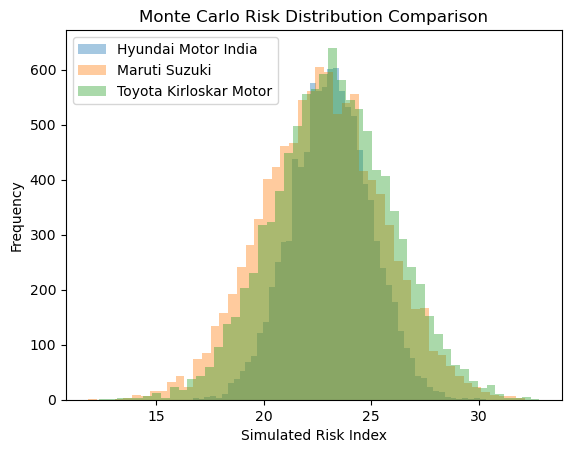

In [25]:
plt.figure()

for company in companies:
    plt.hist(
        results[company]['Simulation'],
        bins=50,
        alpha=0.4,
        label=company
    )

plt.title("Monte Carlo Risk Distribution Comparison")
plt.xlabel("Simulated Risk Index")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# Stress Test

In [26]:
def monte_carlo_stress(data, shock_dict=None, n_simulations=10000):
    
    incident_mean = data['Incident_Count'].mean()
    incident_std = data['Incident_Count'].std()
    
    severity_mean = data['Avg_Severity'].mean()
    severity_std = data['Avg_Severity'].std()
    
    text_mean = data['Avg_Text_Risk'].mean()
    text_std = data['Avg_Text_Risk'].std()
    
    # Apply shocks if provided
    if shock_dict is not None:
        incident_mean *= (1 + shock_dict.get('incident', 0))
        severity_mean *= (1 + shock_dict.get('severity', 0))
        text_mean *= (1 + shock_dict.get('text', 0))
    
    simulated_risk = []
    
    for _ in range(n_simulations):
        
        sim_incident = np.random.normal(incident_mean, incident_std)
        sim_severity = np.random.normal(severity_mean, severity_std)
        sim_text = np.random.normal(text_mean, text_std)
        
        risk_index = (
            0.5 * sim_incident +
            0.3 * sim_severity +
            0.2 * sim_text
        )
        
        simulated_risk.append(risk_index)
    
    simulated_risk = np.array(simulated_risk)
    
    mean_risk = np.mean(simulated_risk)
    var_95 = np.percentile(simulated_risk, 95)
    
    return simulated_risk, mean_risk, var_95


In [27]:
stress_scenarios = {
    "Logistics Shock (+30%)": {'incident': 0.30},
    "Quality Shock (+25%)": {'severity': 0.25},
    "Systemic Supply Crisis (+20%)": {
        'incident': 0.20,
        'severity': 0.20,
        'text': 0.20
    }
}


In [28]:
stress_results = {}

for company in companies:
    
    company_data = monthly_data[monthly_data['Company'] == company]
    
    stress_results[company] = {}
    
    for scenario_name, shock in stress_scenarios.items():
        
        _, mean_risk, var_95 = monte_carlo_stress(company_data, shock)
        
        stress_results[company][scenario_name] = {
            'Mean Risk': mean_risk,
            'VaR 95%': var_95
        }


In [29]:
for company in companies:
    print("\n", company)
    
    baseline_mean = results[company]['Mean Risk']
    
    for scenario in stress_scenarios:
        stressed_mean = stress_results[company][scenario]['Mean Risk']
        increase = ((stressed_mean - baseline_mean) / baseline_mean) * 100
        
        print(f"{scenario}: {increase:.2f}% increase in Expected Risk")



 Hyundai Motor India
Logistics Shock (+30%): 18.21% increase in Expected Risk
Quality Shock (+25%): 1.05% increase in Expected Risk
Systemic Supply Crisis (+20%): 20.07% increase in Expected Risk

 Maruti Suzuki
Logistics Shock (+30%): 17.92% increase in Expected Risk
Quality Shock (+25%): 1.06% increase in Expected Risk
Systemic Supply Crisis (+20%): 19.83% increase in Expected Risk

 Toyota Kirloskar Motor
Logistics Shock (+30%): 18.37% increase in Expected Risk
Quality Shock (+25%): 0.96% increase in Expected Risk
Systemic Supply Crisis (+20%): 20.18% increase in Expected Risk
